# 01 – Exploratory Data Analysis

**CTU-UHB Intrapartum Cardiotocography Database**
https://physionet.org/content/ctu-uhb-ctgdb/1.0.0/

Goals of this notebook:
1. Load all 552 recordings and parse clinical metadata
2. Understand signal length, sampling rate, missing value patterns
3. Visualise 5–10 raw FHR + UC traces
4. Count positive cases at each pH threshold (7.05, 7.15, 7.20)
5. Record findings in `docs/notes.md`


In [1]:
import sys
from pathlib import Path

if "__file__" in globals():
    PROJECT_ROOT = Path(__file__).resolve().parents[1]
else:
    PROJECT_ROOT = Path.cwd().resolve()
    if PROJECT_ROOT.name == "notebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from src.data_loading import (
    build_metadata_table,
    get_record_names,
    load_record,
    resolve_data_dir,
    FS,
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.3f}".format)

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "physionet.org" / "files" / "ctu-uhb-ctgdb" / "1.0.0"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


def _longest_gap_seconds(fhr: np.ndarray, fs: float) -> float:
    """Return duration (s) of the longest consecutive NaN run."""
    is_nan = np.isnan(fhr)
    if not is_nan.any():
        return 0.0
    changes = np.diff(np.r_[False, is_nan, False].astype(int))
    starts = np.flatnonzero(changes == 1)
    ends = np.flatnonzero(changes == -1)
    return float((ends - starts).max() / fs)


## 1  Load metadata table


In [2]:
print("Building metadata table from all .hea files — this takes ~30 s …")
df = build_metadata_table(RAW_DIR)
print(f"Loaded {len(df)} recordings.")
df.head()


Building metadata table from all .hea files — this takes ~30 s …


Loaded 552 recordings.


,record,pH,BDecf,pCO2,BE,Apgar1,Apgar5,weight,sex,age,gravidity,parity,Meconium,Presentation,Delivery,dbID,n_samples,duration_min,fs
0,1001,7.140,8.140,7.700,-10.500,6.000,8.000,2660.000,2,32.000,1.000,0.000,0,2,1,974204,19200,80.000,4
1,1002,7.000,7.920,12.000,-12.000,8.000,8.000,2900.000,2,23.000,1.000,0.000,1,1,1,975666,19200,80.000,4
2,1003,7.200,3.030,8.300,-5.600,7.000,9.000,3770.000,1,31.000,1.000,0.000,0,1,1,982315,18000,75.000,4
3,1004,7.300,5.190,5.500,-6.400,8.000,9.000,3370.000,1,36.000,1.000,0.000,1,1,1,983277,16800,70.000,4
4,1005,7.300,4.520,5.700,-5.800,9.000,10.000,3550.000,2,28.000,1.000,0.000,0,1,1,983398,18000,75.000,4


## 2  Data quality checks

These checks run before signal exploration and modelling. They identify
duplicate records, incomplete file pairs, missing metadata, invalid pH
values, and inconsistent sampling rates.


In [3]:
data_dir = resolve_data_dir(RAW_DIR)
dat_names = {path.stem for path in data_dir.glob("*.dat")}
hea_names = {path.stem for path in data_dir.glob("*.hea")}

quality_summary = {
    "metadata_rows": len(df),
    "duplicate_record_ids": int(df["record"].duplicated().sum()),
    "duplicate_metadata_rows": int(df.duplicated().sum()),
    "dat_files": len(dat_names),
    "hea_files": len(hea_names),
    "dat_without_header": len(dat_names - hea_names),
    "header_without_dat": len(hea_names - dat_names),
    "missing_metadata_cells": int(df.isna().sum().sum()),
    "missing_pH": int(df["pH"].isna().sum()),
    "invalid_pH": int(((df["pH"] < 6.5) | (df["pH"] > 8.0)).sum()),
    "non_4Hz_records": int((df["fs"] != FS).sum()),
}
quality_df = pd.Series(quality_summary, name="count").to_frame()
display(quality_df)

missing_by_column = df.isna().sum().rename("missing_count").to_frame()
missing_by_column["missing_percent"] = missing_by_column["missing_count"] / len(df) * 100
display(missing_by_column[missing_by_column["missing_count"] > 0])

assert quality_summary["duplicate_record_ids"] == 0
assert quality_summary["duplicate_metadata_rows"] == 0
assert quality_summary["dat_without_header"] == 0
assert quality_summary["header_without_dat"] == 0
assert quality_summary["missing_pH"] == 0
assert quality_summary["invalid_pH"] == 0
assert quality_summary["non_4Hz_records"] == 0


,count
metadata_rows,552
duplicate_record_ids,0
duplicate_metadata_rows,0
dat_files,552
hea_files,552
dat_without_header,0
header_without_dat,0
missing_metadata_cells,38
missing_pH,0
invalid_pH,0


,missing_count,missing_percent
BDecf,11,1.993
pCO2,11,1.993
BE,11,1.993
weight,1,0.181
gravidity,4,0.725


In [4]:
# Persist the quality checks so later phases can cite the exact audit.
quality_df.to_csv(PROCESSED_DIR / "data_quality_summary.csv")
missing_by_column.to_csv(PROCESSED_DIR / "data_quality_missing_by_column.csv")
print(f"Data-quality checks passed for {len(df)} recordings.")


Data-quality checks passed for 552 recordings.


In [5]:
print("=== Dataset shape ===")
print(f"Recordings : {len(df)}")
print(f"Columns    : {list(df.columns)}")
print()
print("=== Missing values ===")
print(df.isnull().sum().to_string())


=== Dataset shape ===
Recordings : 552
Columns    : ['record', 'pH', 'BDecf', 'pCO2', 'BE', 'Apgar1', 'Apgar5', 'weight', 'sex', 'age', 'gravidity', 'parity', 'Meconium', 'Presentation', 'Delivery', 'dbID', 'n_samples', 'duration_min', 'fs']

=== Missing values ===
record           0
pH               0
BDecf           11
pCO2            11
BE              11
Apgar1           0
Apgar5           0
weight           1
sex              0
age              0
gravidity        4
parity           0
Meconium         0
Presentation     0
Delivery         0
dbID             0
n_samples        0
duration_min     0
fs               0


## 3  Signal properties


In [6]:
print("=== Recording duration (minutes) ===")
print(df["duration_min"].describe())
print()
print("=== Sampling rate (Hz) — should all be 4 ===")
print(df["fs"].value_counts())


=== Recording duration (minutes) ===
count   552.000
mean     74.163
std       7.558
min      60.000
25%      70.000
50%      71.708
75%      80.000
max      90.083
Name: duration_min, dtype: float64

=== Sampling rate (Hz) — should all be 4 ===
fs
4    552
Name: count, dtype: int64


In [7]:
# Flag recordings that are very short (< 10 min usable signal)
short_mask = df["duration_min"] < 10
print(f"Recordings shorter than 10 min: {short_mask.sum()}")


Recordings shorter than 10 min: 0


## 4  Cord pH distribution


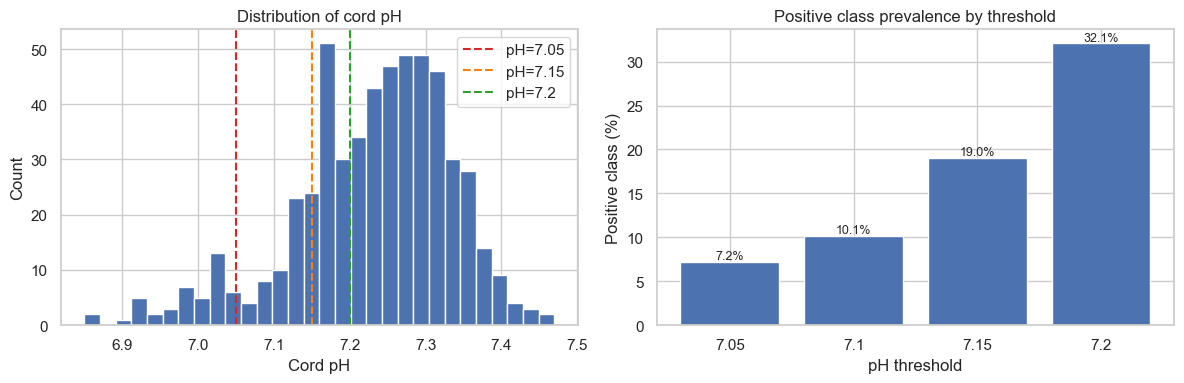

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["pH"].dropna(), bins=30, color="#4C72B0", edgecolor="white")
for thresh, color in [(7.05, "#d62728"), (7.15, "#ff7f0e"), (7.20, "#2ca02c")]:
    axes[0].axvline(thresh, color=color, linestyle="--", linewidth=1.5, label=f"pH={thresh}")
axes[0].set_xlabel("Cord pH")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of cord pH")
axes[0].legend()

# Positive class prevalence at each threshold
thresholds = [7.05, 7.10, 7.15, 7.20]
prevalences = [(df["pH"] < t).mean() * 100 for t in thresholds]
axes[1].bar([str(t) for t in thresholds], prevalences, color="#4C72B0", edgecolor="white")
axes[1].set_xlabel("pH threshold")
axes[1].set_ylabel("Positive class (%)")
axes[1].set_title("Positive class prevalence by threshold")
for i, v in enumerate(prevalences):
    axes[1].text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_ph_distribution.png", dpi=150)
plt.show()


In [9]:
# Label counts — print clearly for docs
print("=== Label counts by pH threshold ===")
print(f"{'Threshold':<12} {'Positive (n)':<15} {'Negative (n)':<15} {'Prevalence'}")
print("-" * 55)
ph_valid = df["pH"].dropna()
for t in [7.05, 7.10, 7.15, 7.20]:
    pos = (ph_valid < t).sum()
    neg = (ph_valid >= t).sum()
    prev = pos / len(ph_valid) * 100
    print(f"pH < {t:<7.2f} {pos:<15} {neg:<15} {prev:.1f}%")

print(f"\nRecordings with missing pH: {df['pH'].isnull().sum()}")


=== Label counts by pH threshold ===
Threshold    Positive (n)    Negative (n)    Prevalence
-------------------------------------------------------
pH < 7.05    40              512             7.2%
pH < 7.10    56              496             10.1%
pH < 7.15    105             447             19.0%
pH < 7.20    177             375             32.1%

Recordings with missing pH: 0


## 5  Missing signal analysis


In [10]:
print("Computing per-recording signal loss — this takes ~1 min …")

signal_stats = []
for rec in get_record_names(RAW_DIR):
    try:
        _, fhr, uc = load_record(rec, RAW_DIR)
        # Treat 0 and physiologically implausible values as missing
        fhr_nan = fhr.copy()
        fhr_nan[(fhr_nan <= 0) | (fhr_nan < 50) | (fhr_nan > 220)] = np.nan
        pct_missing = np.isnan(fhr_nan).mean() * 100
        longest_gap = _longest_gap_seconds(fhr_nan, FS)
        signal_stats.append({
            "record": rec,
            "pct_fhr_missing": pct_missing,
            "longest_gap_s": longest_gap,
            "n_samples": len(fhr),
        })
    except Exception as e:
        signal_stats.append({"record": rec, "pct_fhr_missing": None,
                              "longest_gap_s": None, "n_samples": None})

sig_df = pd.DataFrame(signal_stats)
df = df.merge(sig_df, on="record", how="left")

print("=== FHR missing signal (%) ===")
print(df["pct_fhr_missing"].describe())


Computing per-recording signal loss — this takes ~1 min …


=== FHR missing signal (%) ===
count   552.000
mean     18.834
std      12.364
min       0.000
25%       9.006
50%      18.360
75%      27.121
max      53.502
Name: pct_fhr_missing, dtype: float64


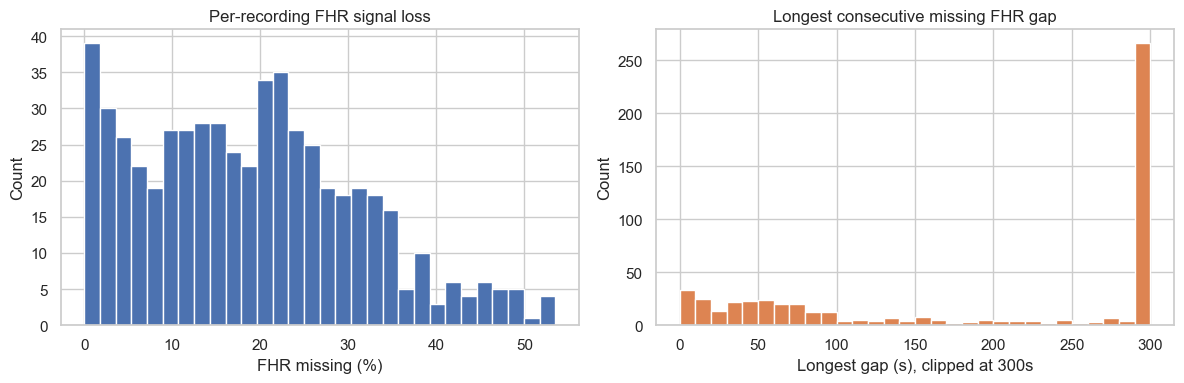

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["pct_fhr_missing"].dropna(), bins=30, color="#4C72B0", edgecolor="white")
axes[0].set_xlabel("FHR missing (%)")
axes[0].set_ylabel("Count")
axes[0].set_title("Per-recording FHR signal loss")

axes[1].hist(df["longest_gap_s"].dropna().clip(upper=300), bins=30,
             color="#dd8452", edgecolor="white")
axes[1].set_xlabel("Longest gap (s), clipped at 300s")
axes[1].set_ylabel("Count")
axes[1].set_title("Longest consecutive missing FHR gap")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_signal_quality.png", dpi=150)
plt.show()


## 6  Plot sample traces


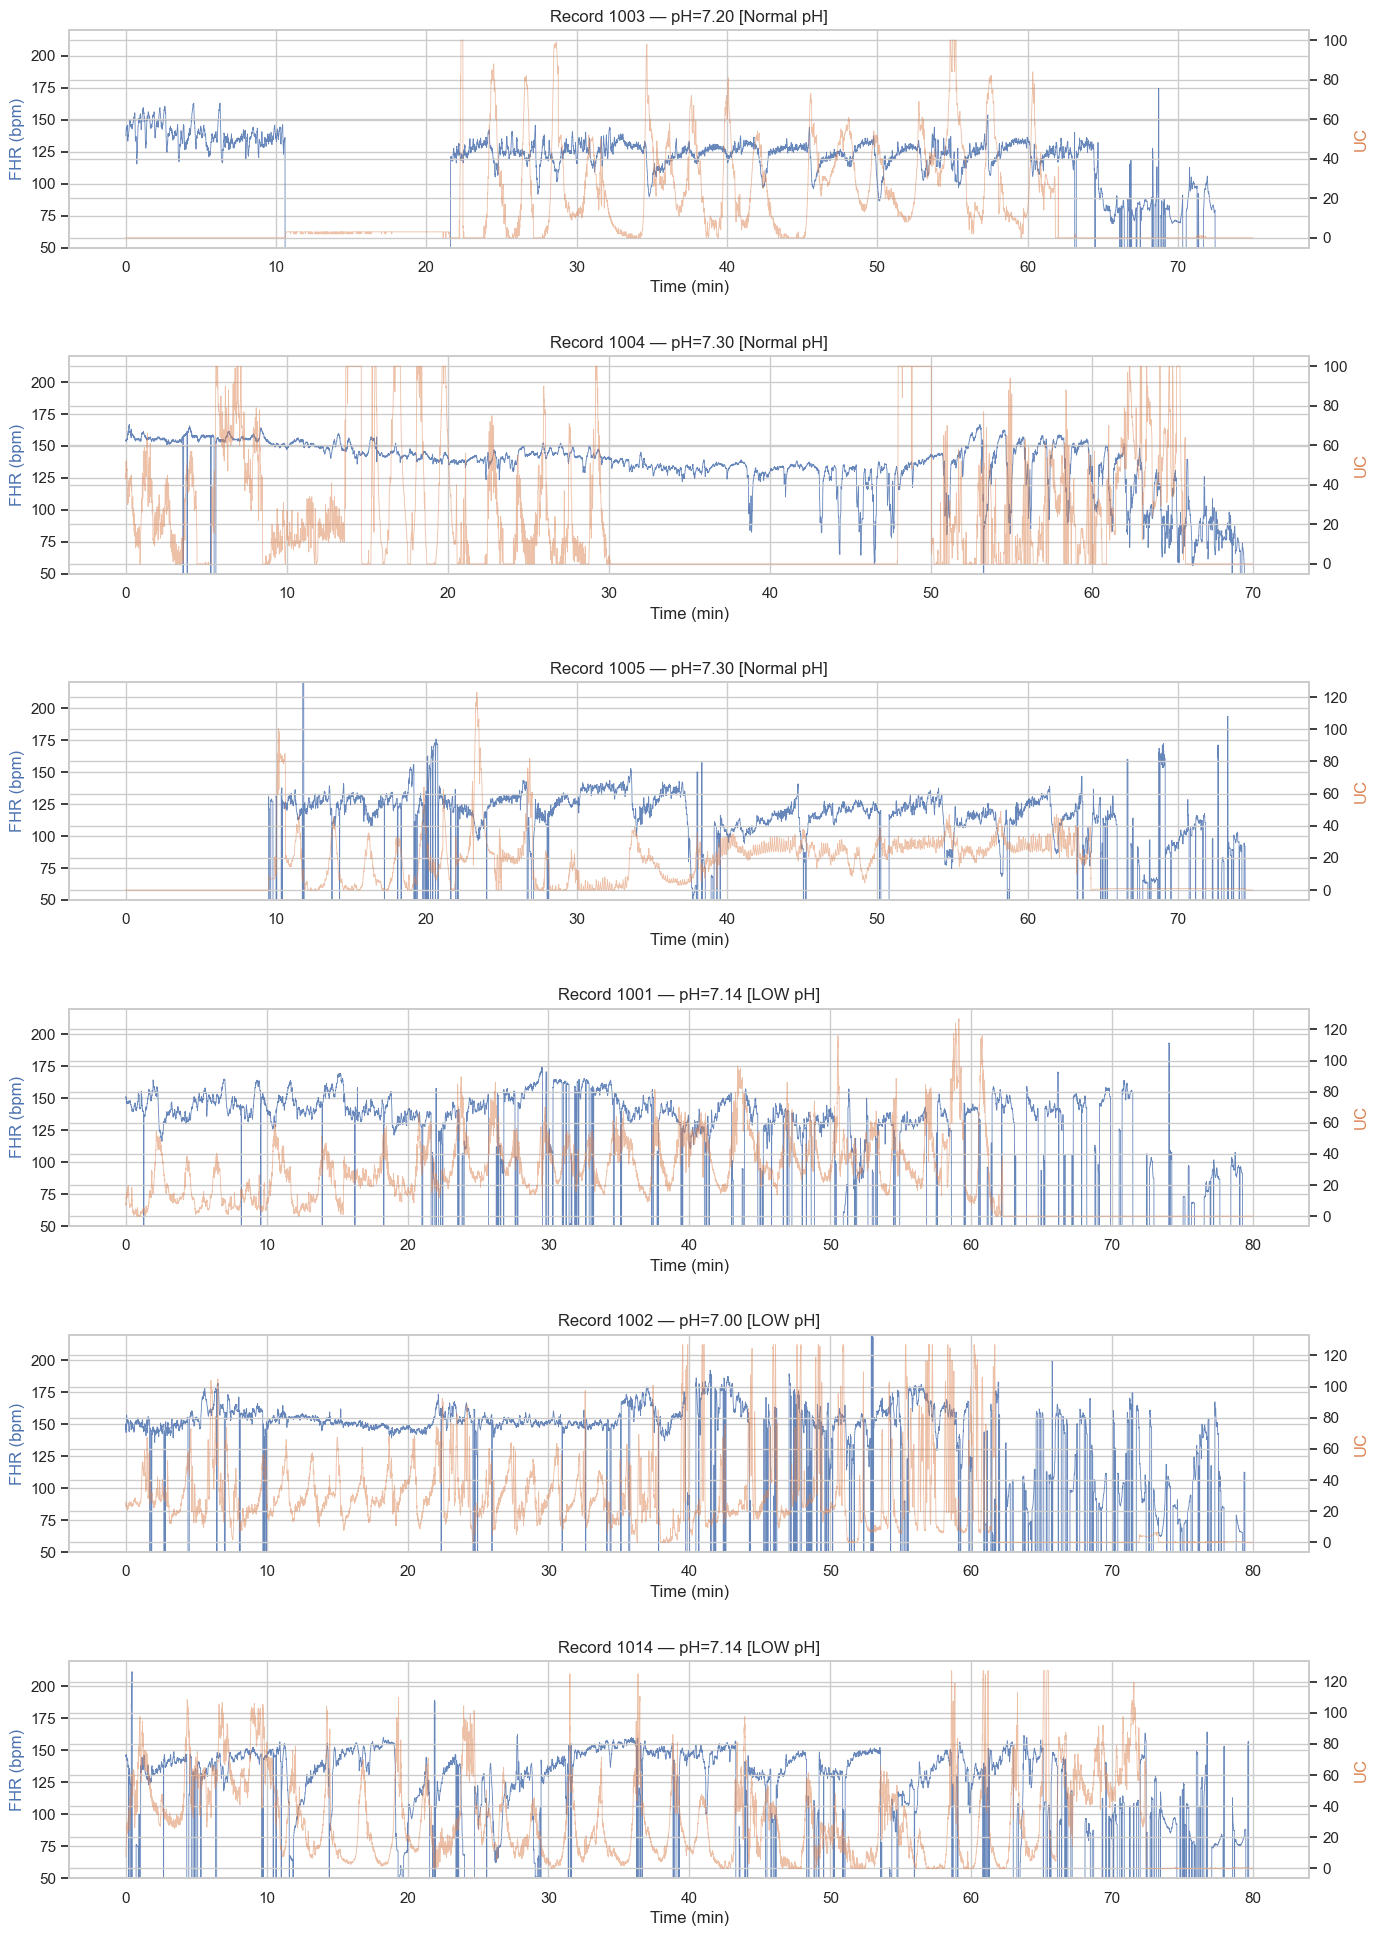

In [12]:
# Select a diverse set: 3 normal pH, 3 low pH (< 7.15), 1 borderline
sample_normal = df[df["pH"] >= 7.15]["record"].dropna().head(3).tolist()
sample_low    = df[df["pH"] <  7.15]["record"].dropna().head(3).tolist()
sample_records = sample_normal + sample_low

fig = plt.figure(figsize=(16, 4 * len(sample_records)))
gs = gridspec.GridSpec(len(sample_records), 1, hspace=0.5)

for i, rec in enumerate(sample_records):
    _, fhr, uc = load_record(rec, RAW_DIR)
    t = np.arange(len(fhr)) / FS / 60  # minutes

    ax_fhr = fig.add_subplot(gs[i])
    ax_uc  = ax_fhr.twinx()

    ph_val = df.loc[df["record"] == rec, "pH"].values
    ph_str = f"pH={ph_val[0]:.2f}" if len(ph_val) else "pH=?"
    label_str = "LOW pH" if ph_val[0] < 7.15 else "Normal pH" if len(ph_val) else ""

    ax_fhr.plot(t, fhr, color="#4C72B0", linewidth=0.6, alpha=0.85, label="FHR")
    ax_uc.plot(t,  uc,  color="#dd8452", linewidth=0.6, alpha=0.5,  label="UC")

    ax_fhr.set_ylim(50, 220)
    ax_fhr.set_ylabel("FHR (bpm)", color="#4C72B0")
    ax_uc.set_ylabel("UC", color="#dd8452")
    ax_fhr.set_xlabel("Time (min)")
    ax_fhr.set_title(f"Record {rec} — {ph_str} [{label_str}]")

plt.savefig(FIGURES_DIR / "01_sample_traces.png", dpi=120, bbox_inches="tight")
plt.show()


## 7  Other clinical variables


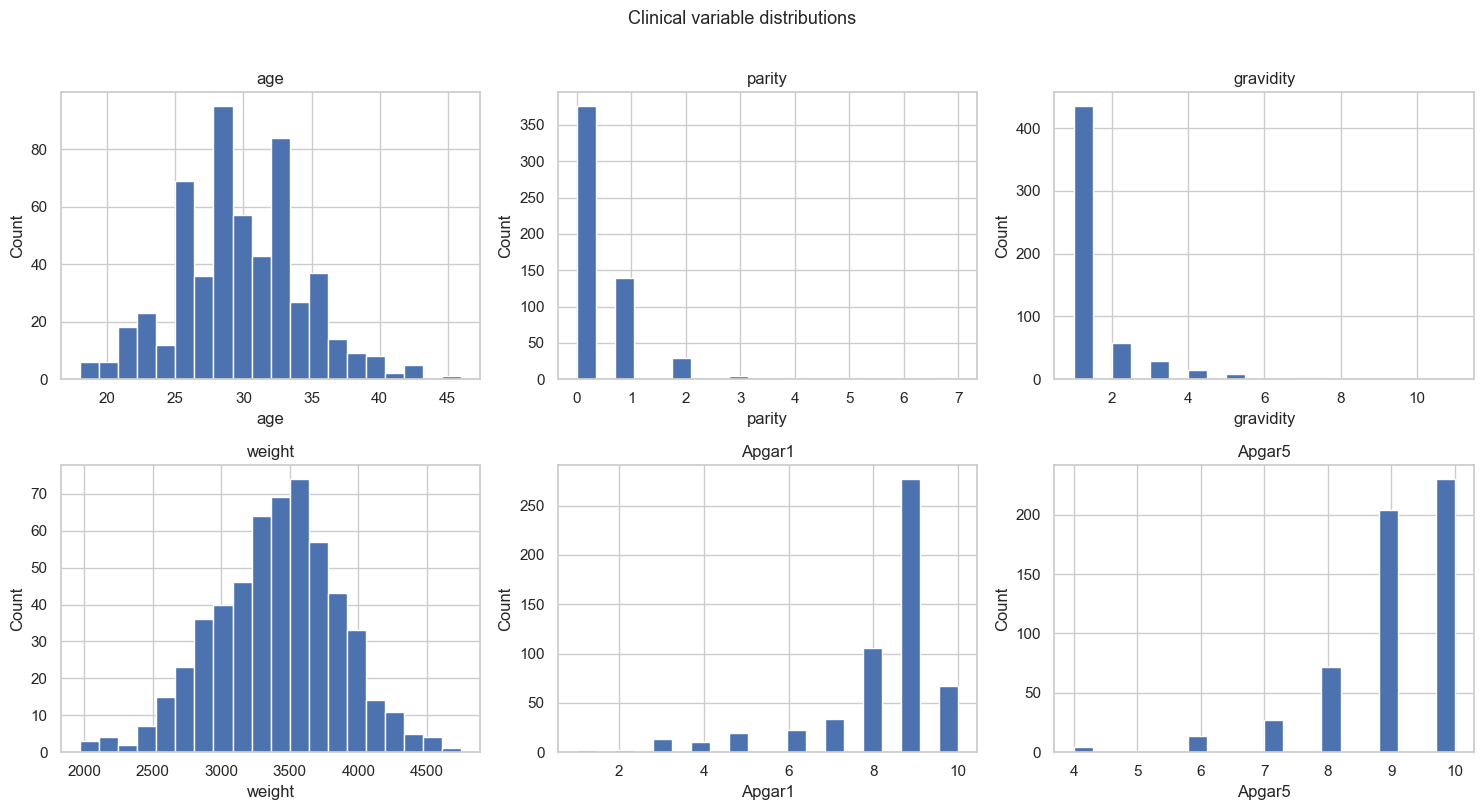

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

vars_to_plot = ["age", "parity", "gravidity", "weight", "Apgar1", "Apgar5"]
for ax, var in zip(axes, vars_to_plot):
    ax.hist(df[var].dropna(), bins=20, color="#4C72B0", edgecolor="white")
    ax.set_title(var)
    ax.set_xlabel(var)
    ax.set_ylabel("Count")

plt.suptitle("Clinical variable distributions", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_clinical_vars.png", dpi=150)
plt.show()


In [14]:
if "Delivery" in df.columns:
    print("=== Delivery type ===")
    print(df["Delivery"].value_counts())
if "Meconium" in df.columns:
    print("\n=== Meconium staining ===")
    print(df["Meconium"].value_counts())


=== Delivery type ===
Delivery
1    506
2     46
Name: count, dtype: int64

=== Meconium staining ===
Meconium
0    488
1     64
Name: count, dtype: int64


In [15]:
# Save reproducible Phase 1 tables for later preprocessing/modeling phases.
df.to_csv(PROCESSED_DIR / "metadata_eda.csv", index=False)
print(f"Saved metadata and signal-quality table to {PROCESSED_DIR / 'metadata_eda.csv'}")


Saved metadata and signal-quality table to D:\SideProjects\Navo\data\processed\metadata_eda.csv


## 8  Save processed metadata


In [16]:
out_path = PROCESSED_DIR / "metadata.csv"
df.to_csv(out_path, index=False)
print(f"Saved metadata to {out_path}  ({len(df)} rows × {len(df.columns)} cols)")


Saved metadata to D:\SideProjects\Navo\data\processed\metadata.csv  (552 rows × 22 cols)


## 9  Summary for docs/notes.md

Results are recorded in `docs/notes.md`, `docs/label_definition.md`, and
`docs/exclusion_rules.md`. The analysis-window decision remains Phase 2 work.
